# 02 — Stationarity, transformations, seasonality and model identification

**Milestone M4.** For each of the 8 products, this notebook decides how the series must be prepared before ARIMA/SARIMA modelling (M5):

1. whether to **transform** it (log1p),
2. whether to apply **seasonal differencing** (D, weekly period s = 7),
3. whether to apply **ordinary differencing** (d),
4. which **AR/MA orders** the ACF/PACF suggest.

**Leakage rule.** Identification runs separately at each forecast origin (d_1800, d_1828, d_1856, d_1885), using only the 730 days before that origin. M5 uses the record for the matching origin. This notebook shows the d_1800 results, plus a stability check across all four origins.

All logic is in `src/optichain/diagnostics.py`. The same results are produced by `scripts/run_diagnostics.py`, which writes `models/identification.json`.

In [1]:
%matplotlib inline
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from optichain import diagnostics as D
from optichain import plots as P
from optichain.config import PROJECT_ROOT, load_config
from optichain.data_pipeline import get_series

P.apply_style()
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
cfg = load_config()
ITEMS, ORIGIN, WINDOW = cfg.series.items, min(cfg.forecast.origins), cfg.forecast.fit_window_days
long = pd.read_parquet(cfg.data.processed_dir / "selected_series.parquet")
classes = pd.read_csv(PROJECT_ROOT / "reports/metrics/ca_1_demand_classes.csv").set_index("item_id")["demand_class"]
ident = pd.read_csv(PROJECT_ROOT / "reports/metrics/identification.csv")
first = ident[ident["origin_d"] == ORIGIN].set_index("item_id")
print(f"origin d_{ORIGIN}, window {WINDOW} days, alpha {cfg.diagnostics.alpha}")

origin d_1800, window 730 days, alpha 0.05


## 0. Data preparation: store-closure days

Every M5 store sells **zero units on 25 December** because it is closed. That zero is not demand. After a log transform it becomes a huge outlier: it inflated the rolling spread, distorted the stationarity tests and dominated the STL remainder in a first run of this analysis.

For modelling and simulation, `get_series(..., fill_closures=True)` replaces each closure day with the **same weekday one week earlier**. This uses only past data, so there is no leakage. Descriptive EDA (notebook 01) keeps the raw series. The forecast windows (January–April) contain no closures, so evaluation is unaffected.

In [2]:
raw = get_series(long, "FOODS_3_586", ORIGIN).iloc[-WINDOW:]
filled = get_series(long, "FOODS_3_586", ORIGIN, fill_closures=True).iloc[-WINDOW:]
changed = raw[raw != filled]
display(pd.DataFrame({"raw": changed, "filled (same weekday, 1 week earlier)": filled[changed.index]}))

,raw,"filled (same weekday, 1 week earlier)"
date,,
2014-12-25,0.0,47.0
2015-12-25,0.0,35.0


## 1. The decision procedure

| Step | Rule | Rationale |
|---|---|---|
| Transform | log1p if the 28-day rolling std rises with the 28-day rolling mean (correlation ≥ 0.6) **and** ≤ 10% zero days | Stabilises variance that scales with level. Not used on zero-heavy series, where log1p mainly distorts the zero/non-zero split |
| Seasonal D | D = 1 if STL weekly seasonal strength F_s ≥ 0.64 | Same threshold as Hyndman's `nsdiffs` |
| Seasonal check | If ACF at lags 7, 14, 21, 28 all stay > 0.2, also offer D = 1 as a candidate | A slowly decaying seasonal ACF suggests a seasonal unit root that the strength threshold can miss |
| Ordinary d | ADF (H₀: unit root) and KPSS (H₀: stationary) on the seasonally differenced series | Two tests with opposite nulls guard against over-reading either p-value |

How the two test results combine into a verdict:

| ADF | KPSS | Verdict | d |
|---|---|---|---|
| rejects | does not reject | stationary | 0 |
| does not reject | rejects | unit root | 1 |
| rejects | rejects | **conflict** (level shifts / long memory) | 0, with candidates {0, 1} |
| does not reject | does not reject | **inconclusive** (low power) | 0, with candidates {0, 1} |

**Why candidates instead of a single answer?** AIC/BIC can only compare models fitted to the *same* data, and changing d or D changes the data. So the ambiguous cases are settled in M5 by out-of-sample accuracy on the rolling folds, not by AIC.

> Note: statsmodels reports KPSS p-values only within [0.01, 0.10]. A value of 0.010 means "≤ 0.01" and 0.100 means "≥ 0.10"; the `kpss_p_bound` column records which bound was hit.

## 2. Results at d_1800

In [3]:
cols = ["demand_class", "zero_share", "var_level_corr", "transform", "level_adf_p", "level_kpss_p", "level_verdict",
        "seasonal_strength", "trend_strength", "D", "pre_d_verdict", "d", "lb_p_7", "lb_p_14", "white_noise",
        "p_hint", "q_hint", "P_hint", "Q_hint"]
display(first[cols])
idj = json.loads((PROJECT_ROOT / "models/identification.json").read_text())
display(pd.DataFrame({i: {"d candidates": idj[i][str(ORIGIN)]["d_candidates"],
                          "D candidates": idj[i][str(ORIGIN)]["D_candidates"]} for i in ITEMS}).T)

,demand_class,zero_share,var_level_corr,transform,level_adf_p,level_kpss_p,level_verdict,seasonal_strength,trend_strength,D,pre_d_verdict,d,lb_p_7,lb_p_14,white_noise,p_hint,q_hint,P_hint,Q_hint
item_id,,,,,,,,,,,,,,,,,,,
FOODS_3_586,smooth,0.000,0.833,log1p,1.273e-01,0.010,unit_root,0.588,0.497,0,unit_root,1,3.448e-39,8.399e-66,False,2,2,0,1
HOUSEHOLD_1_447,smooth,0.052,0.485,none,9.026e-03,0.010,conflict,0.259,0.326,0,conflict,0,5.972e-30,3.689e-54,False,2,2,1,1
FOODS_3_203,smooth,0.079,0.730,log1p,4.156e-05,0.100,stationary,0.320,0.285,0,stationary,0,1.005e-17,8.521e-24,False,1,2,1,1
HOBBIES_1_189,erratic,0.162,0.675,none,3.545e-06,0.010,conflict,0.084,0.087,0,conflict,0,1.300e-03,1.003e-04,False,0,0,0,0
HOBBIES_1_030,erratic,0.201,0.873,none,3.842e-03,0.010,conflict,0.150,0.105,0,conflict,0,3.171e-06,3.724e-11,False,0,0,1,1
HOUSEHOLD_1_469,intermittent,0.371,0.817,none,5.103e-11,0.010,conflict,0.170,0.146,0,conflict,0,3.112e-03,2.110e-03,False,1,1,1,0
FOODS_3_242,intermittent,0.512,0.658,none,0.000e+00,0.100,stationary,0.145,0.103,0,stationary,0,3.419e-01,3.875e-01,True,0,0,0,0
HOUSEHOLD_1_046,lumpy,0.359,0.660,none,0.000e+00,0.059,stationary,0.078,0.019,0,stationary,0,2.689e-01,4.315e-01,True,0,0,0,0


,d candidates,D candidates
FOODS_3_586,[1],"[0, 1]"
HOUSEHOLD_1_447,"[0, 1]",[0]
FOODS_3_203,[0],[0]
HOBBIES_1_189,"[0, 1]",[0]
HOBBIES_1_030,"[0, 1]",[0]
HOUSEHOLD_1_469,"[0, 1]",[0]
FOODS_3_242,[0],[0]
HOUSEHOLD_1_046,[0],[0]


**Reading the table**

- **No product passes the seasonal-strength threshold** (F_s = 0.08–0.59), even though notebook 01 found strong weekend peaks. Daily noise is large compared with the weekly pattern, so seasonal differencing is not the default. The weekly pattern goes into seasonal AR/MA terms (P, Q with s = 7) instead.
- **FOODS_3_586** (the high-volume item) is the exception. Its seasonal ACF barely decays (0.38, 0.38, 0.37, 0.35 at lags 7–28), so D = 1 is kept as a candidate. It is also the only clear **unit root** case: ADF p = 0.13 and KPSS rejects, giving d = 1 on the log1p scale.
- **Four items show a conflict** (HOUSEHOLD_1_447, both HOBBIES items, HOUSEHOLD_1_469). Both tests reject, which is typical of a stationary series with level shifts, for example HOUSEHOLD_1_447's upward drift. They default to d = 0, and d = 1 is tested out-of-sample in M5.
- **FOODS_3_203** is cleanly stationary after log1p.
- **FOODS_3_242 and HOUSEHOLD_1_046 are statistically white noise** (Ljung–Box p = 0.34 and 0.27 at lag 7). There is no autocorrelation for ARIMA to exploit, so the best possible point forecast is close to a well-estimated mean. That explains why the 4-week average already beats the other benchmarks on these items in M3, and it predicts that ARIMA will add little.
- **Transforms:** only the two FOODS items with almost no zero days get log1p. The other series have a strong variance–level link too, but they are zero-heavy (> 10% zero days), where log1p is not appropriate.

## 3. A closer look

### FOODS_3_586: unit root and strong weekly structure

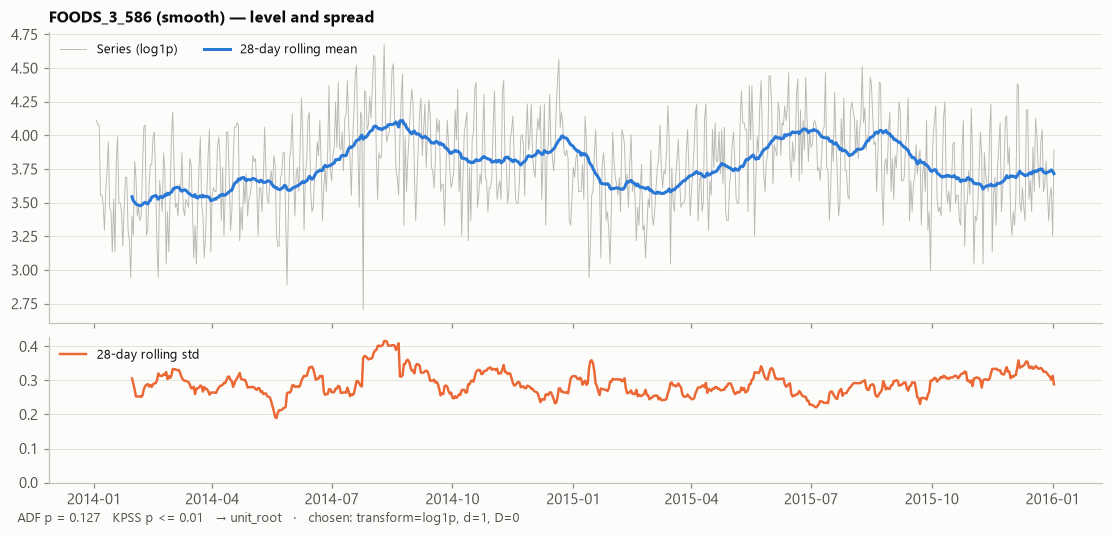

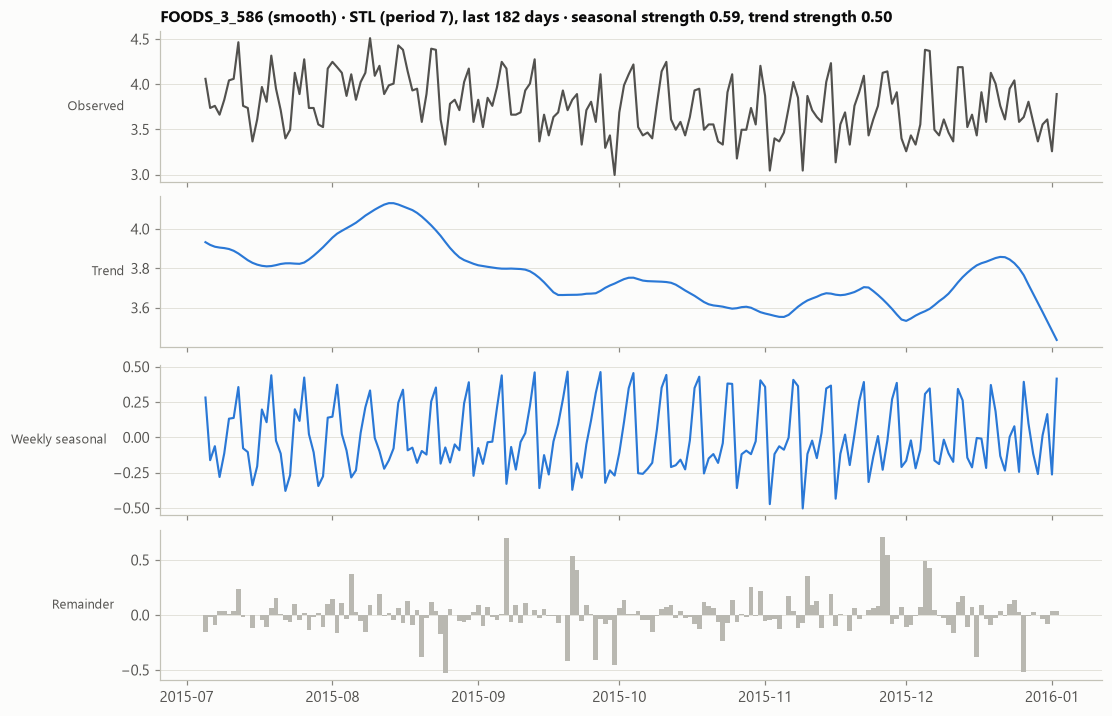

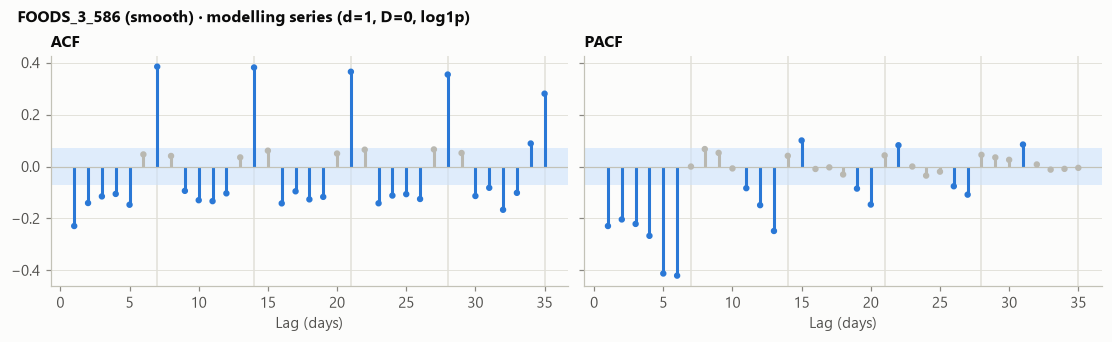

In [4]:
def show_item(item):
    y = get_series(long, item, ORIGIN, fill_closures=True).iloc[-WINDOW:]
    rec = D.identify(y, alpha=cfg.diagnostics.alpha, lb_lags=tuple(cfg.diagnostics.ljung_box_lags))
    label = f"{item} ({classes[item]})"
    D.fig_stationarity(y, rec, f"{label} — level and spread")
    D.fig_stl(y, rec, label)
    D.fig_acf_pacf(D.modelling_series(y, rec), rec, label)
    plt.show()

show_item("FOODS_3_586")

- On the log scale the level drifts with the seasons (summer highs). There is no constant mean to revert to, which is consistent with the unit-root verdict.
- STL shows a clean, stable weekly cycle. The remainder is now small because the Christmas outlier has been removed.
- After first differencing, the ACF has large spikes at **every multiple of 7** that barely decay. The PACF has strong negative values at lags 1–6 and again just before lags 14 and 21.
- Together these point to a **seasonal model**: either SARIMA(p,1,q)(P,0,Q)₇ with a strong seasonal AR term, or seasonal differencing (D = 1). The negative lag-1 ACF (−0.23) is moderate, so first differencing does not look excessive (the usual warning sign is below −0.5).
- **Candidate grid for M5:** p, q ∈ {0, 1, 2}; P, Q ∈ {0, 1}; d = 1; D ∈ {0, 1}.

### HOBBIES_1_189: conflicting tests

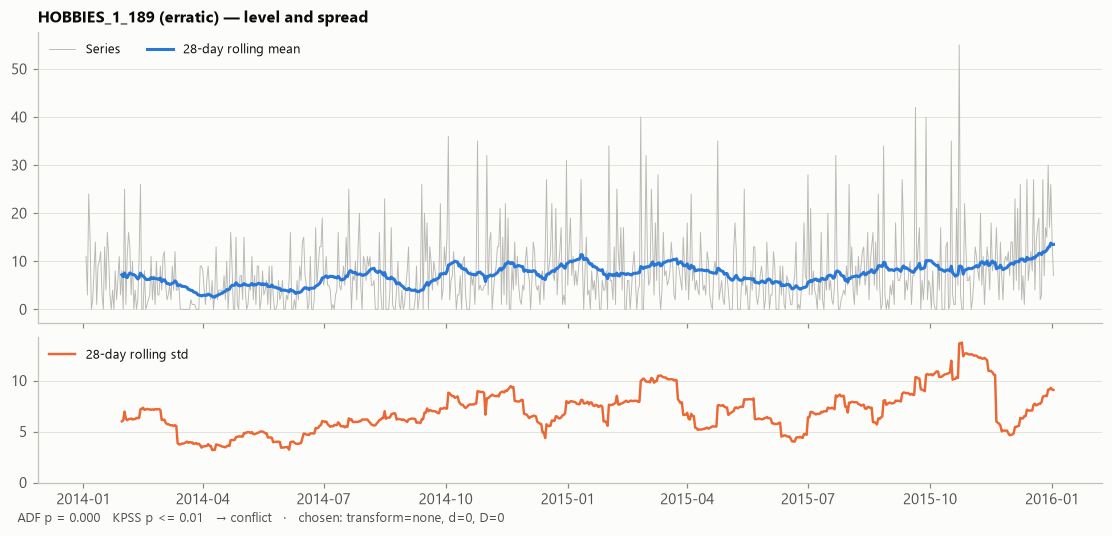

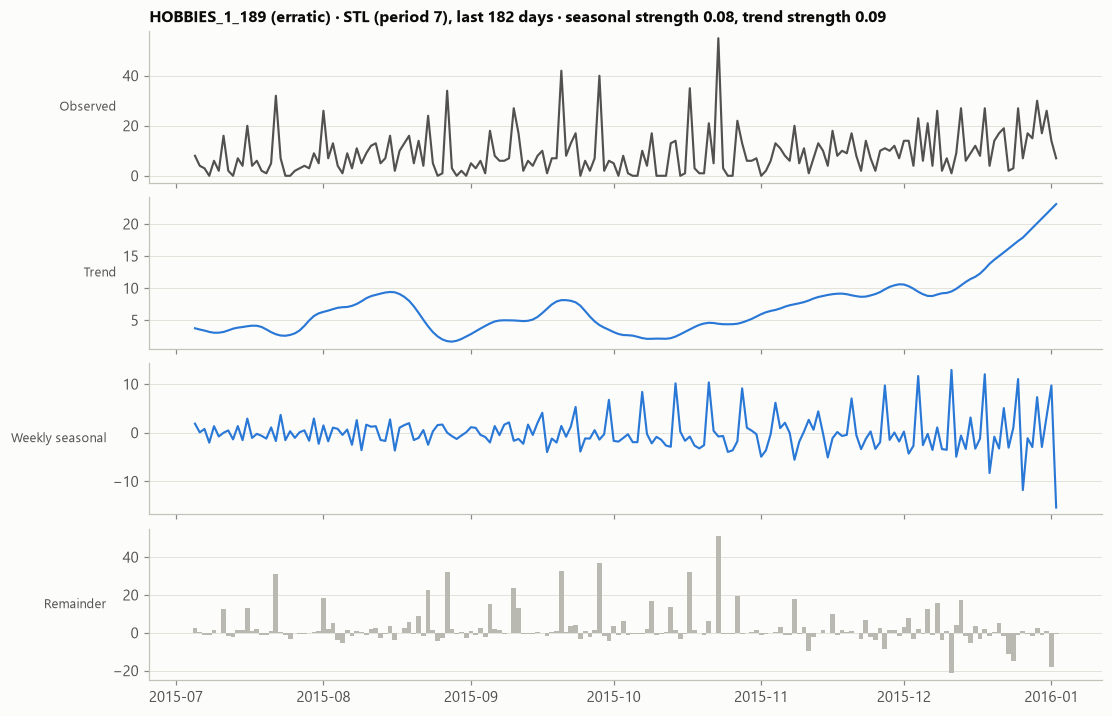

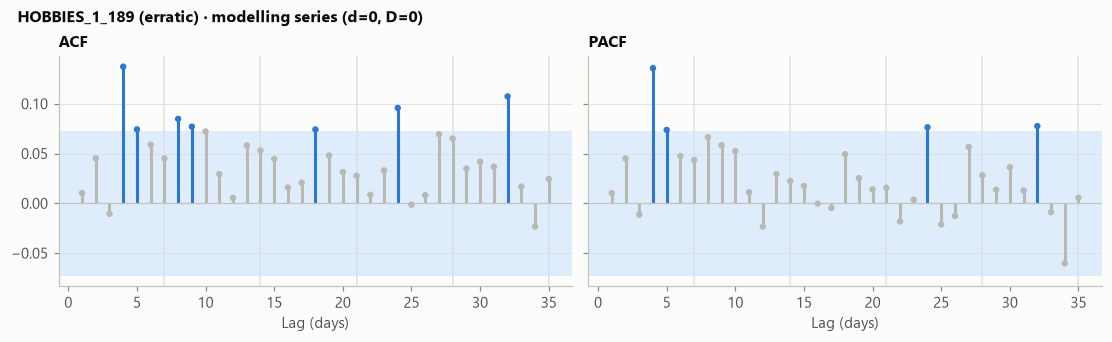

In [5]:
show_item("HOBBIES_1_189")

- The rolling mean shifts level several times, and the rolling spread rises and falls with it.
- ADF rejects a unit root, while KPSS rejects level-stationarity. The tests disagree because neither "stationary around one fixed mean" nor "random walk" fits a series with level shifts.
- The modelling series has only weak autocorrelation: few significant lags and no seasonal spikes (F_s = 0.08). This product barely has a weekly pattern, as notebook 01 also found.
- **M5 plan:** a low-order ARIMA with d ∈ {0, 1} compared out-of-sample. ETS and the moving average are likely to be competitive.

### FOODS_3_242: white noise

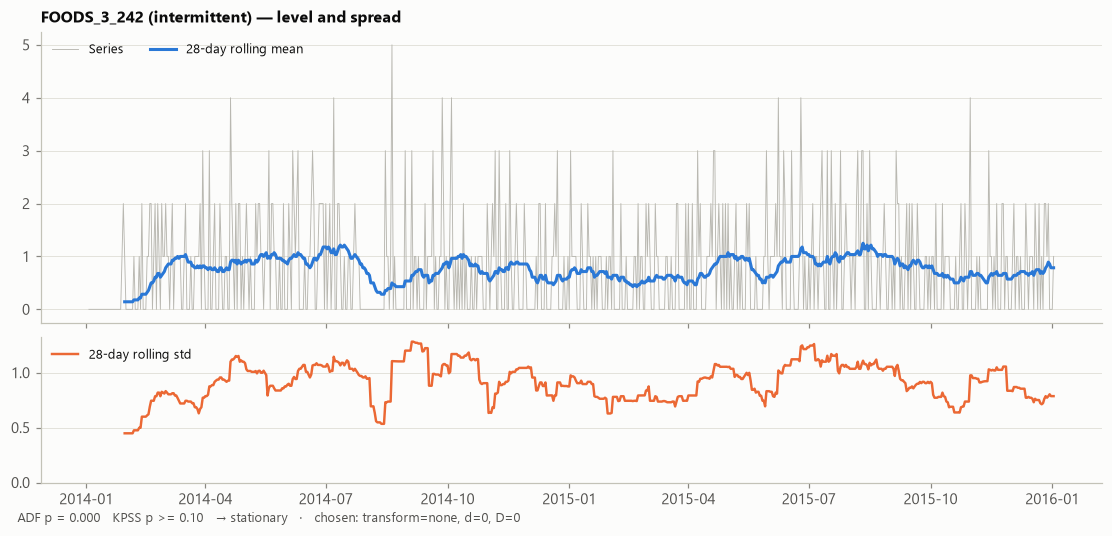

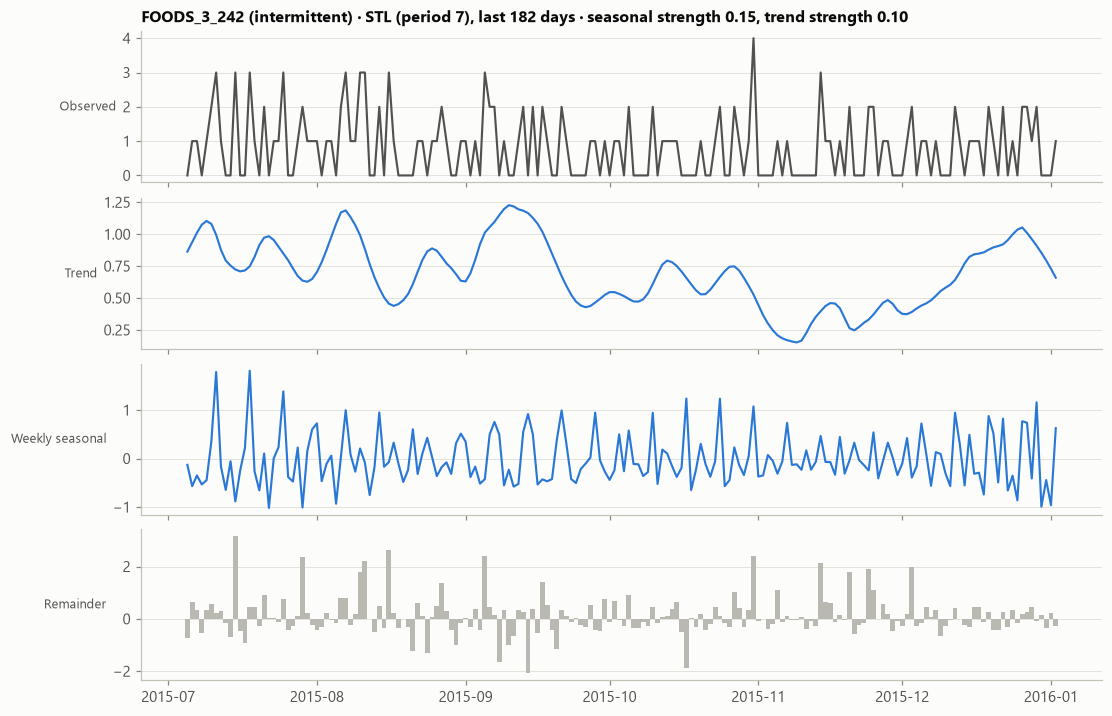

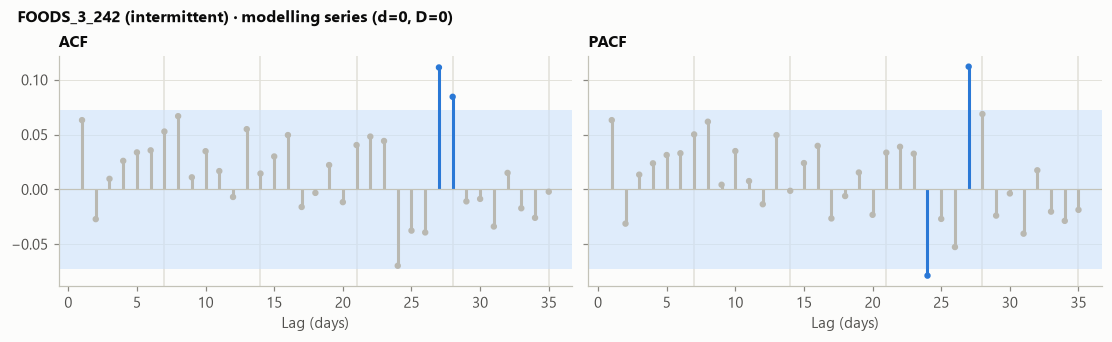

In [6]:
show_item("FOODS_3_242")

- Almost every ACF and PACF bar sits inside the 95% band, and Ljung–Box does not reject white noise.
- For a series like this, the best linear forecast is essentially its mean. More complex models can only add estimation noise.
- **M5 plan:** keep ARIMA(0,0,0) with a constant as the reference, and compare it with Croston/SBA, which is built for intermittent demand.

## 4. Are the decisions stable across origins?

In [7]:
stab = ident.pivot_table(index="item_id", columns="origin_d", values=["d", "D"], aggfunc="first")
display(stab.loc[ITEMS])
display(ident.pivot_table(index="item_id", columns="origin_d", values="seasonal_strength").loc[ITEMS].round(2))

D                   d               
origin_d        1800 1828 1856 1885 1800 1828 1856 1885
item_id                                                
FOODS_3_586        0    0    0    0    1    1    1    1
HOUSEHOLD_1_447    0    0    0    0    0    0    0    1
FOODS_3_203        0    0    0    0    0    0    0    0
HOBBIES_1_189      0    0    0    0    0    0    0    0
HOBBIES_1_030      0    0    0    0    0    0    1    0
HOUSEHOLD_1_469    0    0    0    0    0    0    0    0
FOODS_3_242        0    0    0    0    0    0    0    0
HOUSEHOLD_1_046    0    0    0    0    0    0    0    0

origin_d,1800,1828,1856,1885
item_id,,,,
FOODS_3_586,0.59,0.57,0.57,0.56
HOUSEHOLD_1_447,0.26,0.28,0.27,0.32
FOODS_3_203,0.32,0.33,0.31,0.29
HOBBIES_1_189,0.08,0.08,0.07,0.08
HOBBIES_1_030,0.15,0.13,0.18,0.14
HOUSEHOLD_1_469,0.17,0.15,0.16,0.13
FOODS_3_242,0.15,0.15,0.17,0.16
HOUSEHOLD_1_046,0.08,0.07,0.08,0.09


- **D = 0 at every origin** for every product, and seasonal strength moves by at most 0.06 between origins.
- **d changes for two products at one origin each:** HOUSEHOLD_1_447 at d_1885 and HOBBIES_1_030 at d_1856. Both are already "conflict" items. The flip shows that their stationarity verdict sits close to the 5% boundary, which is why both d values are carried into M5 instead of trusting a single test result.
- Running identification separately at each origin means every model in the backtest uses decisions it could actually have made at that time.

## 5. Summary: what M5 receives

| Product | Transform | d | D | Notes for modelling |
|---|---|---|---|---|
| FOODS_3_586 | log1p | 1 | {0, 1} | Strong weekly structure; SARIMA's main test case |
| HOUSEHOLD_1_447 | none | {0, 1} | 0 | Upward drift; also try damped-trend ETS |
| FOODS_3_203 | log1p | 0 | 0 | Stationary; weekly AR/MA terms suggested |
| HOBBIES_1_189 | none | {0, 1} | 0 | Level shifts, weak weekly pattern |
| HOBBIES_1_030 | none | {0, 1} | 0 | Spiky; ARCH-LM candidate in M6 |
| HOUSEHOLD_1_469 | none | {0, 1} | 0 | Intermittent; possible stockout near d_1800 |
| FOODS_3_242 | none | 0 | 0 | White noise; mean/Croston expected to be best |
| HOUSEHOLD_1_046 | none | 0 | 0 | White noise; mean/Croston expected to be best |

The ACF/PACF hints (`p_hint`, `q_hint`, `P_hint`, `Q_hint`) narrow the search but do not replace it. M5 searches the configured grid (p, q ≤ 2; P, Q ≤ 1) within each allowed (d, D) combination, picks orders by AIC, and then compares families out-of-sample.